In [1]:
%pip install tellurium

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np

from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

import tellurium as te

# Model full

In [15]:
with open("repressilator.ant") as f:
    model1=f.read()

In [16]:
r1=te.loada(model1)

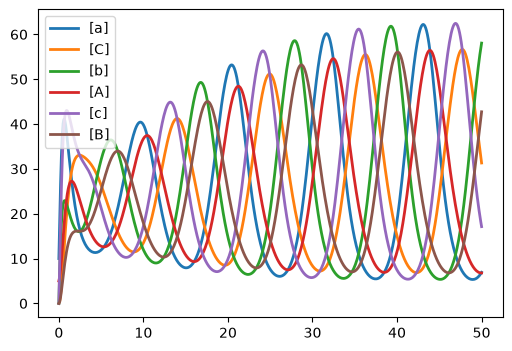

In [17]:
t_end=50
N = t_end*10 # number of samples

result = r1.simulate(0, t_end, N)
r1.plot()

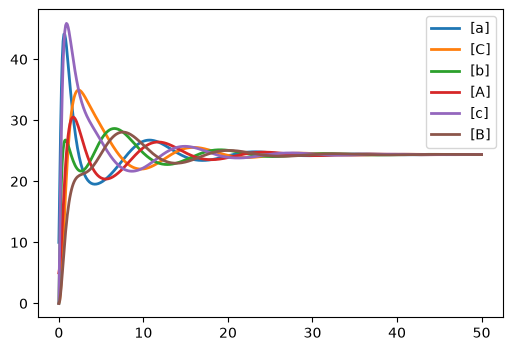

In [18]:
r1.resetToOrigin()

#r.alpha = 100
r1.alpha0 = 0.1
#r.Kd = 10
#r.delta = 1
#r.n = 2

result = r1.simulate(0, t_end, N)
r1.plot()

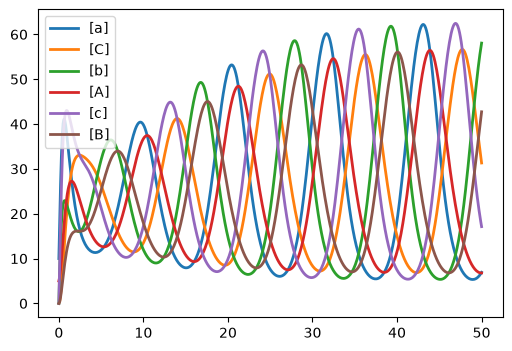

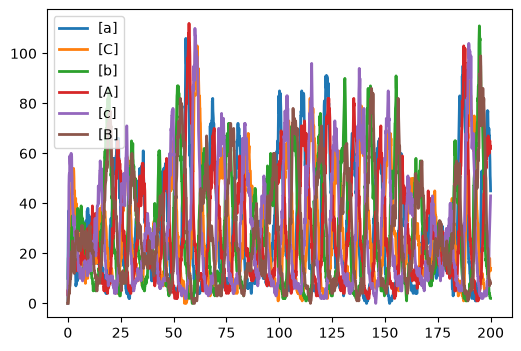

// Created by libAntimony v3.3.0
// Compartments and Species:
species a, C, b, A, c, B;

// Reactions:
tr_a:  -> a; alpha/(1 + (C/Kd)^n);
tr_b:  -> b; alpha/(1 + (A/Kd)^n);
tr_c:  -> c; alpha/(1 + (B/Kd)^n);
tr_a_leak:  -> a; alpha0*alpha;
tr_b_leak:  -> b; alpha0*alpha;
tr_c_leak:  -> c; alpha0*alpha;
deg_a: a -> ; delta_m*a;
deg_b: b -> ; delta_m*b;
deg_c: c -> ; delta_m*c;
tl_a: a -> a + A; beta*a;
tl_b: b -> b + B; beta*b;
tl_c: c -> c + C; beta*c;
deg_A: A -> ; delta*A;
deg_B: B -> ; delta*B;
deg_C: C -> ; delta*C;

// Species initializations:
a = 10;
C = 0;
b = 0;
A = 5;
c = 0;
B = 0;

// Variable initializations:
alpha = 100;
Kd = 10;
n = 2;
alpha0 = 0.01;
delta_m = 1;
beta = 1;
delta = 1;

// Other declarations:
const alpha, Kd, n, alpha0, delta_m, beta, delta;



In [19]:
r=r1

t_end=50
N = t_end*10 # number of samples

r.resetToOrigin()
r.integrator = "cvode"

result = r.simulate(0, t_end, N)
r.plot()

# izracun ravnovesnega stanja
#r.resetToOrigin()
#r.steadyState() 
#print(r.getFloatingSpeciesConcentrations())

# stohasticna simulacija istega modela (glej razdelek o stohasticnem
# modeliranju); velikost reakcijskega prostora dolocimo s compartmentom
r.resetToOrigin()
r.integrator = 'gillespie'
r.integrator.seed = 1234
rezultat_stoh = r.simulate(0, 200, 2000)

r.plot()

# izvoz v standardne formate
r.exportToSBML('repressilator.xml')
print(r.getAntimony())

# Model simple

In [20]:
with open("repressilator_simple.ant") as f:
    model2=f.read()

In [21]:
r2=te.loada(model2)

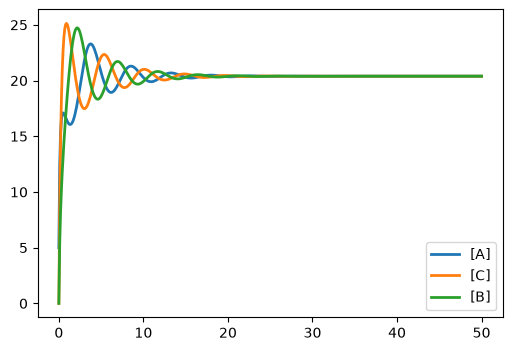

In [22]:
t_end=50
N = t_end*10 # number of samples

#result = r2.simulate(0, t_end, N, ['time', 'A', 'B', 'C'])
result = r2.simulate(0, t_end, N)
r2.plot()

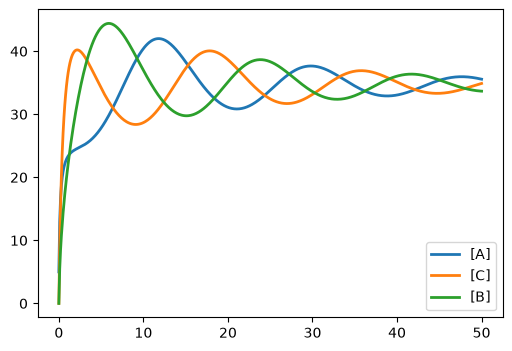

In [23]:
r2.resetToOrigin()

r2.alpha = 100#r1.alpha*r1.beta/r1.delta_m
r2.delta = 0.25

result = r2.simulate(0, t_end, N)
r2.plot()

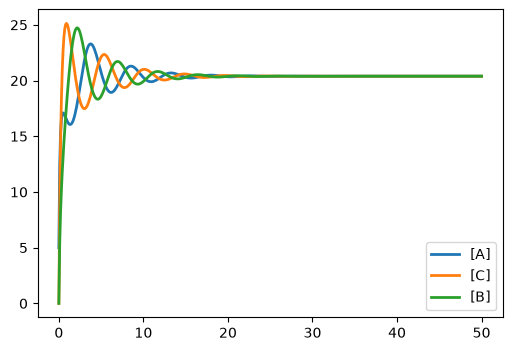

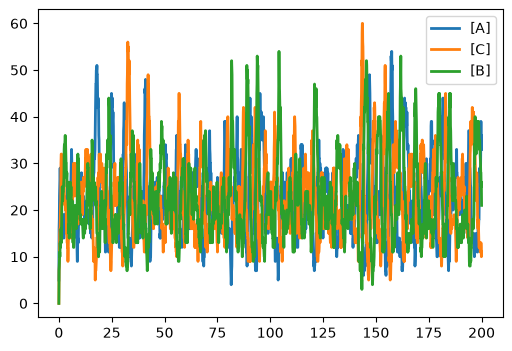

// Created by libAntimony v3.3.0
// Compartments and Species:
species A, C, B;

// Reactions:
exp_A:  -> A; alpha/(1 + (C/Kd)^n) + alpha0*alpha;
exp_B:  -> B; alpha/(1 + (A/Kd)^n) + alpha0*alpha;
exp_C:  -> C; alpha/(1 + (B/Kd)^n) + alpha0*alpha;
deg_A: A -> ; delta*A;
deg_B: B -> ; delta*B;
deg_C: C -> ; delta*C;

// Species initializations:
A = 5;
C = 0;
B = 0;

// Variable initializations:
alpha = 100;
Kd = 10;
n = 2;
alpha0 = 0.01;
delta = 1;

// Other declarations:
const alpha, Kd, n, alpha0, delta;



In [24]:
r=r2

t_end=50
N = t_end*10 # number of samples

r.resetToOrigin()
r.integrator = "cvode"

result = r.simulate(0, t_end, N)
r.plot()

# izracun ravnovesnega stanja
r.resetToOrigin()
#r.steadyState() 
#print(r.getFloatingSpeciesConcentrations())


# stohasticna simulacija istega modela (glej razdelek o stohasticnem
# modeliranju); velikost reakcijskega prostora dolocimo s compartmentom
r.resetToOrigin()
r.integrator = 'gillespie'
r.integrator.seed = 1234
rezultat_stoh = r.simulate(0, 200, 2000)
r.plot()

# izvoz v standardne formate
r.exportToSBML('repressilator.xml')
print(r.getAntimony())